In [1]:
import numpy as np
from scipy.io import loadmat
import warnings
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

In [2]:
!pip install pandas
!pip install resonator_tools

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import circuit

In [4]:
import os
os.chdir(r"C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-012")   # paste your copied path here
print(os.getcwd())
print(os.listdir())   # should now list Freq_f1.mat etc.

C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-012
['f0_guess.mat', 'Freq_f1.mat', 'Freq_f2.mat', 'Freq_f3.mat', 'I1_f1.mat', 'I1_f2.mat', 'I1_f3.mat', 'S21_mag_f1.mat', 'S21_mag_f2.mat', 'S21_mag_f3.mat', 'S21_phase_f1.mat', 'S21_phase_f2.mat', 'S21_phase_f3.mat', 'TC-Main-012-6p5', 'TC-Main-012-7GHz', 'TC-Main-012_fit-v1.ipynb']


In [5]:
# Files
File_S21_mag_s1     = 'S21_mag_f1.mat'
File_S21_mag_s2     = 'S21_mag_f2.mat'
File_S21_mag_s3     = 'S21_mag_f3.mat'
File_S21_phase_s1   = 'S21_phase_f1.mat'
File_S21_phase_s2   = 'S21_phase_f2.mat'
File_S21_phase_s3   = 'S21_phase_f3.mat'
FILE_FREQ_s1        = 'Freq_f1.mat'
FILE_FREQ_s2        = 'Freq_f2.mat'
FILE_FREQ_s3        = 'Freq_f3.mat'
FILE_CURRENT_s1     = 'I1_f1.mat'
FILE_CURRENT_s2     = 'I1_f2.mat'
FILE_CURRENT_s3     = 'I1_f3.mat'


Mat_Freq_s1     = loadmat(FILE_FREQ_s1, squeeze_me=True)
Mat_Freq_s2     = loadmat(FILE_FREQ_s2, squeeze_me=True)
Mat_Freq_s3     = loadmat(FILE_FREQ_s3, squeeze_me=True)
Mat_Current_s1  = loadmat(FILE_CURRENT_s1, squeeze_me=True)
Mat_Current_s2  = loadmat(FILE_CURRENT_s2, squeeze_me=True)
Mat_Current_s3  = loadmat(FILE_CURRENT_s3, squeeze_me=True)
Mat_mag_s1  = loadmat(File_S21_mag_s1, squeeze_me=True)
Mat_mag_s2  = loadmat(File_S21_mag_s2, squeeze_me=True)
Mat_mag_s3  = loadmat(File_S21_mag_s3, squeeze_me=True)
Mat_phase_s1 = loadmat(File_S21_phase_s1, squeeze_me=True)
Mat_phase_s2 = loadmat(File_S21_phase_s2, squeeze_me=True)
Mat_phase_s3 = loadmat(File_S21_phase_s3, squeeze_me=True)

# Mat_F0_Guess = loadmat(File_F0_Guess, squeeze_me=True)
S21_mag_f1 = Mat_mag_s1['S21_filtered_fit_1'] 
S21_mag_f2 = Mat_mag_s2['S21_filtered_fit_2']
S21_mag_f3 = Mat_mag_s3['S21_filtered_fit_3']
S21_phase_f1 = Mat_phase_s1['S21_filtered_phase_fit_1']
S21_phase_f2 = Mat_phase_s2['S21_filtered_phase_fit_2']
S21_phase_f3 = Mat_phase_s3['S21_filtered_phase_fit_3']
Freq_f1 = Mat_Freq_s1['Freq_filtered_f1']
Freq_f2 = Mat_Freq_s2['Freq_filtered_f2']
Freq_f3 = Mat_Freq_s3['Freq_filtered_f3']
I1_s1  = Mat_Current_s1['I1_s1']
I1_s2  = Mat_Current_s2['I1_s2']
I1_s3  = Mat_Current_s3['I1_s3']
# f0_guess = Mat_F0_Guess['dips']
# Mat_phase_s1
#Mat_Complex
S21_complex_f1 = 10**(S21_mag_f1/20) * np.exp(1j * S21_phase_f1)
S21_complex_f2 = 10**(S21_mag_f2/20) * np.exp(1j * S21_phase_f2)
S21_complex_f3 = 10**(S21_mag_f3/20) * np.exp(1j * S21_phase_f3)
S21_complex_f1.shape[1], S21_complex_f2.shape[1], S21_complex_f3.shape[1]

(32, 9, 32)

In [6]:
print("Freq_f1:", Freq_f3.shape)
print("S21_mag_f1:", S21_mag_f1.shape, " S21_phase_f1:", S21_phase_f1.shape)
print("S21_complex_f1:", S21_complex_f1.shape)
print("I1_s1:", I1_s1.shape)

Freq_f1: (401,)
S21_mag_f1: (401, 32)  S21_phase_f1: (401, 32)
S21_complex_f1: (401, 32)
I1_s1: (32,)


In [7]:
def fit_notch_trace(freq, z_complex, electric_delay_guess=None):
    """
    Fit one current trace using resonator_tools' notch (through-line) model.
    Returns (results_dict, (f_sorted, z_sorted, port)).
    """
    order = np.argsort(freq)
    f = np.asarray(freq)[order]
    z = np.asarray(z_complex)[order]
    port = circuit.notch_port()
    port.add_data(f, z)

    # Fit
    try:
        if electric_delay_guess is not None:
            port.autofit(electric_delay=electric_delay_guess)
        else:
            port.autofit()
    except Exception:
        # fallback for older versions
        port.fit()

    resdict = getattr(port, 'fitresults', None)
    if resdict is None:
        resdict = getattr(port, 'results', None)

    def get_d(keys):
        if isinstance(resdict, dict):
            for k in keys:
                if k in resdict:
                    v = np.asarray(resdict[k]).squeeze()
                    if v.size == 1:
                        return v.item()
        return None

    def get_a(keys):
        for k in keys:
            if hasattr(port, k):
                v = np.asarray(getattr(port, k)).squeeze()
                if v.size == 1:
                    return v.item()
        return None

    f0 = get_d(('fr','f0','fr_fit')) or get_a(('fr','f0','fr_fit'))
    Ql = get_d(('Ql','Q','Q_loaded')) or get_a(('Ql','Q','Q_loaded'))
    # Use the corrected internal Q if available
    Qi = get_d(('Qi_dia_corr','Qi','Qi_no_corr')) or get_a(('Qi_dia_corr','Qi','Qi_no_corr'))
    # External Q: prefer diameter-corrected if provided, else absQc
    Qc = get_d(('Qc_dia_corr','absQc')) or get_a(('Qc_dia_corr','absQc'))
    # Asymmetry angle and baseline phase
    phi = get_d(('phi0','phi')) or get_a(('phi0','phi'))
    delay = get_d(('delay','electrical_delay')) or get_a(('delay','electrical_delay'))

    # If Qi missing but Ql and Qc present, compute fallback (real-coupling assumption)
    if (Qi is None) and (Ql is not None) and (Qc is not None) and (Qc > Ql):
        Qi = (Ql * Qc) / (Qc - Ql)

    out = dict(
        f0=(float(f0) if f0 is not None and np.isfinite(f0) else None),
        Ql=(float(Ql) if Ql is not None and np.isfinite(Ql) else None),
        Qi=(float(Qi) if Qi is not None and np.isfinite(Qi) else None),
        Qc=(float(Qc) if Qc is not None and np.isfinite(Qc) else None),
        phi=(float(phi) if phi is not None and np.isfinite(phi) else np.nan),
        delay=(float(delay) if delay is not None and np.isfinite(delay) else np.nan),
        npoints=len(freq),
    )
    return out, (np.asarray(freq), np.asarray(z_complex), port)


In [ ]:
# from scipy.signal import medfilt
# f0_smooth = medfilt(f0_guess, kernel_size=5)  # odd kernel; tune size
# f0_smooth, f0_guess

In [8]:
fit_results_dict = {}
ports_dict = {}   # optional, if you want to re-plot a specific trace later without refitting
fit_results_dict_2 = {}
ports_dict_2 = {}   # optional, if you want to re-plot a specific trace later without refitting
fit_results_dict_3 = {}
ports_dict_3 = {}   # optional, if you want to re-plot a specific
for i in range(S21_complex_f1.shape[1]):
    f_sub = Freq_f1
    s_sub = S21_complex_f1[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict[i] = port_i.fitresults
        ports_dict[i] = port_i
    except Exception as e:
        print(f"I1={I1_s1[i]:.3g} mA: fit failed ({e})")
        fit_results_dict[i] = None


for i in range(S21_complex_f2.shape[1]):
    f_sub = Freq_f2
    s_sub = S21_complex_f2[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict_2[i] = port_i.fitresults
        ports_dict_2[i] = port_i
    except Exception as e:
        print(f"I1={I1_s2[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_2[i] = None

for i in range(S21_complex_f3.shape[1]):
    f_sub = Freq_f3
    s_sub = S21_complex_f3[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict_3[i] = port_i.fitresults
        ports_dict_3[i] = port_i
    except Exception as e:
        print(f"I1={I1_s3[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_3[i] = None



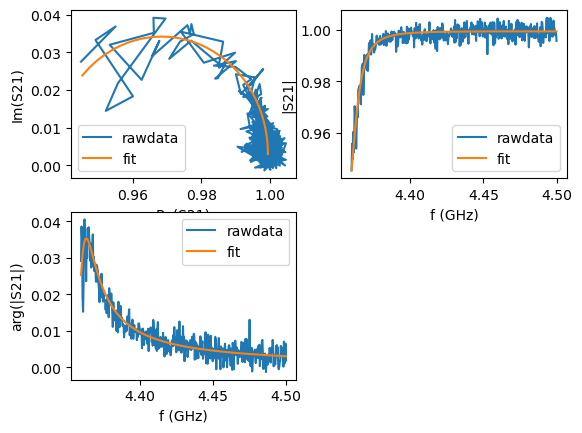

0
I1=1.14 mA: f0=4357856018.429070 Hz, Ql=334


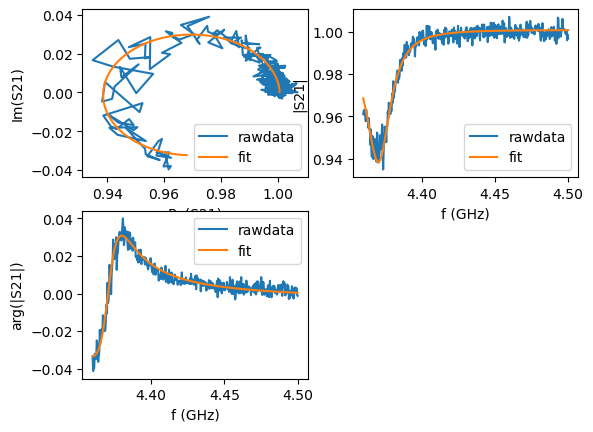

1
I1=1.2 mA: f0=4370854911.220787 Hz, Ql=212


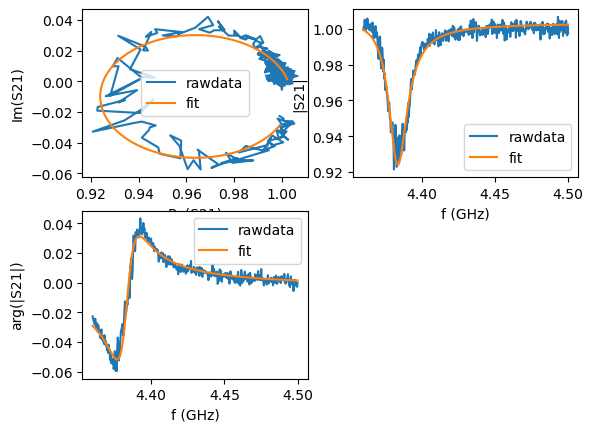

2
I1=1.26 mA: f0=4383033522.275949 Hz, Ql=280


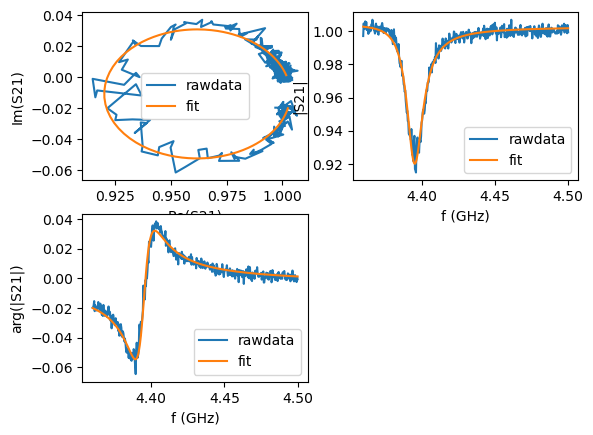

3
I1=1.32 mA: f0=4394636484.595499 Hz, Ql=322


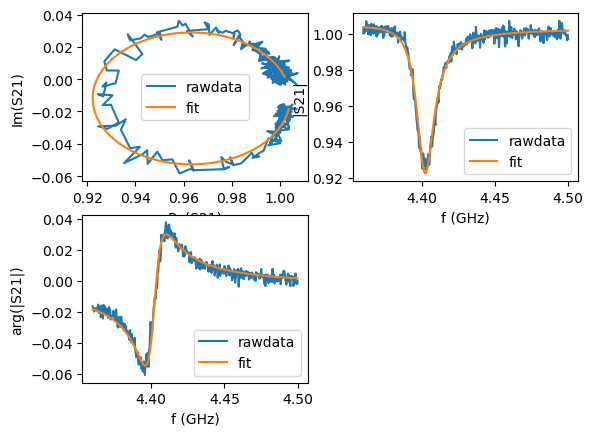

4
I1=1.38 mA: f0=4401665160.647291 Hz, Ql=300


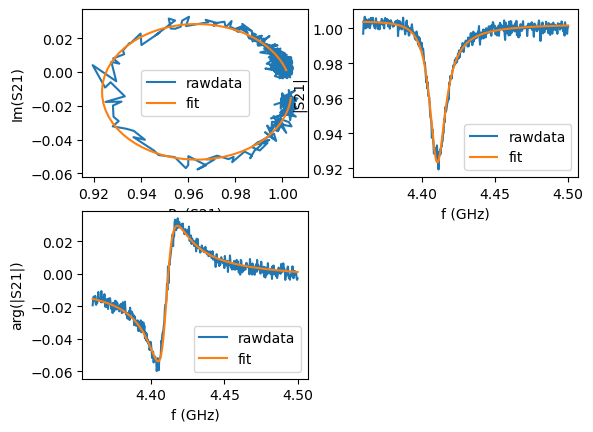

5
I1=1.44 mA: f0=4410037820.047286 Hz, Ql=326


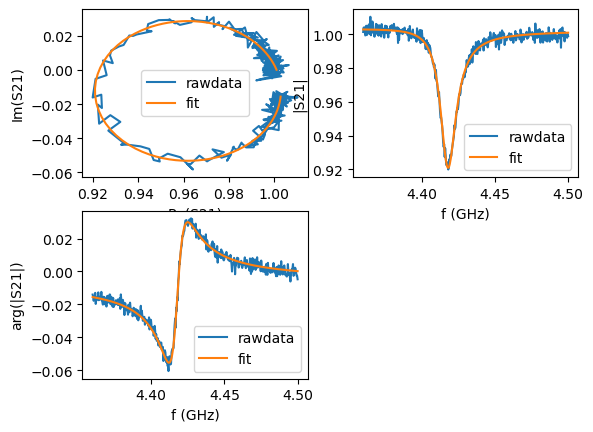

6
I1=1.5 mA: f0=4417494763.567422 Hz, Ql=333


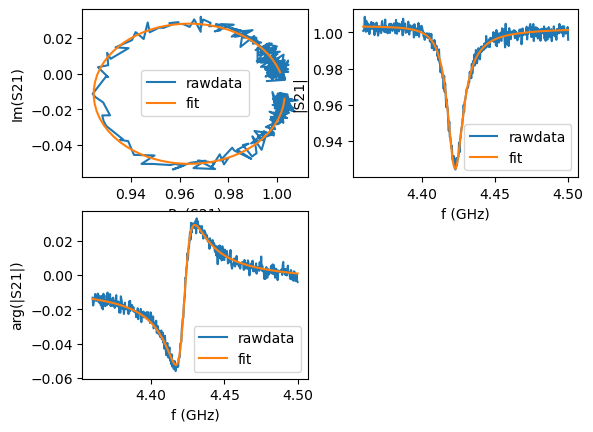

7
I1=1.56 mA: f0=4422315081.844707 Hz, Ql=333


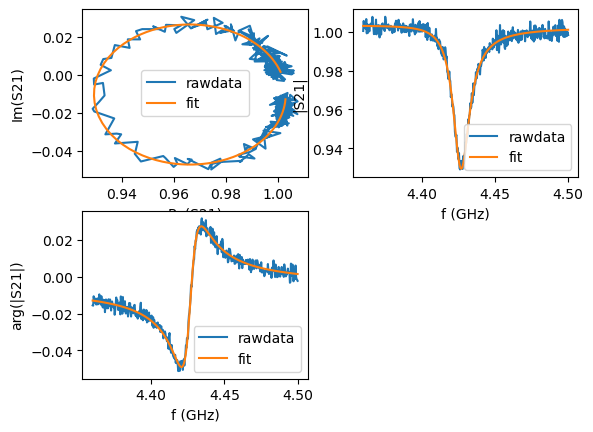

8
I1=1.62 mA: f0=4426422966.423684 Hz, Ql=318


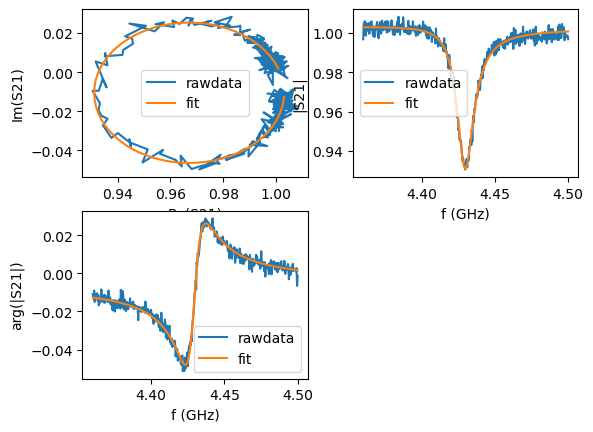

9
I1=1.68 mA: f0=4429168682.947348 Hz, Ql=308


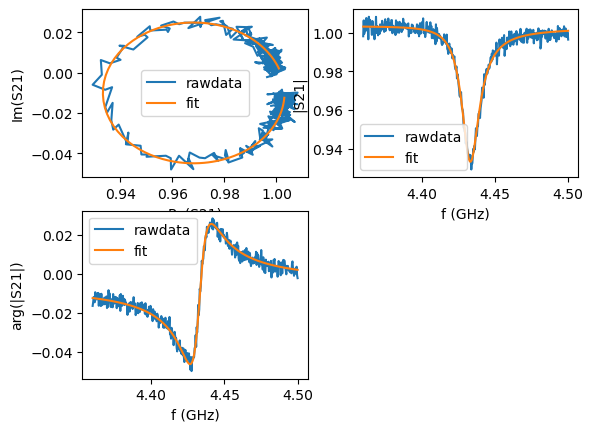

10
I1=1.74 mA: f0=4432736338.590959 Hz, Ql=298


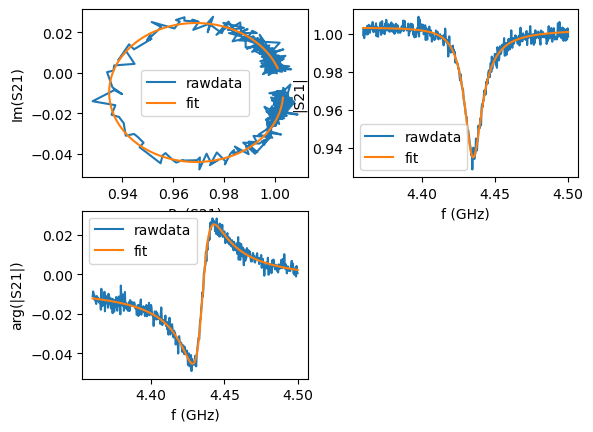

11
I1=1.8 mA: f0=4434601307.363877 Hz, Ql=294


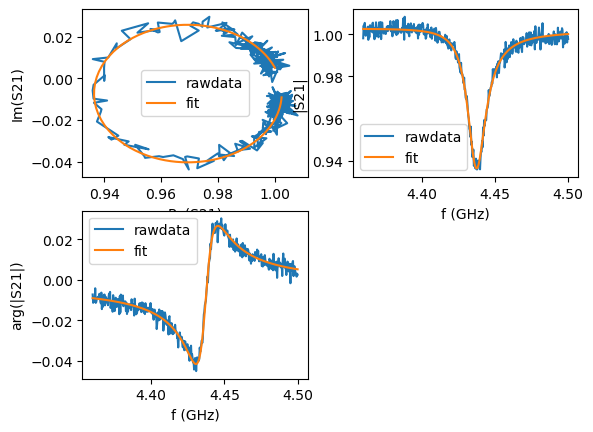

12
I1=1.86 mA: f0=4436904872.527929 Hz, Ql=289


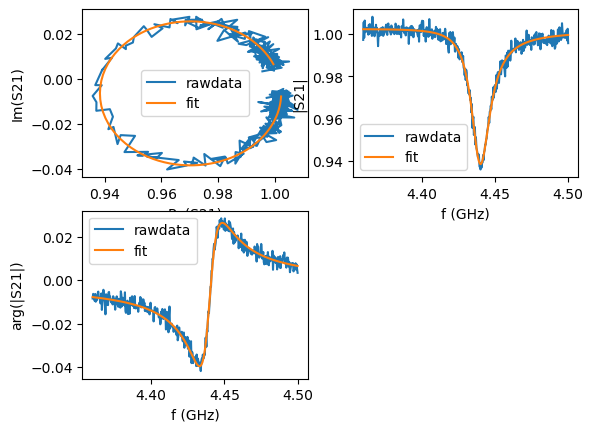

13
I1=1.92 mA: f0=4439522975.456809 Hz, Ql=280


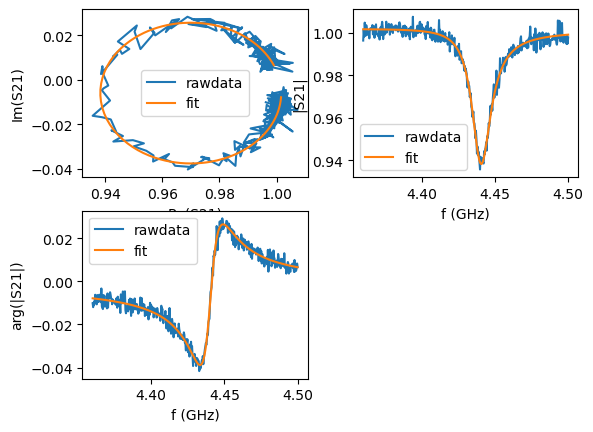

14
I1=1.98 mA: f0=4440075867.396359 Hz, Ql=276


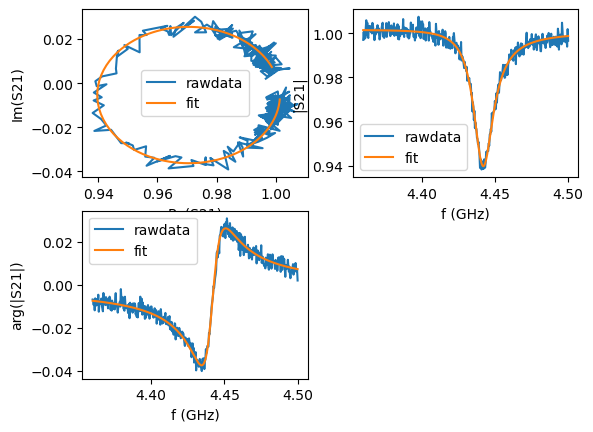

15
I1=2.04 mA: f0=4441446441.210084 Hz, Ql=265


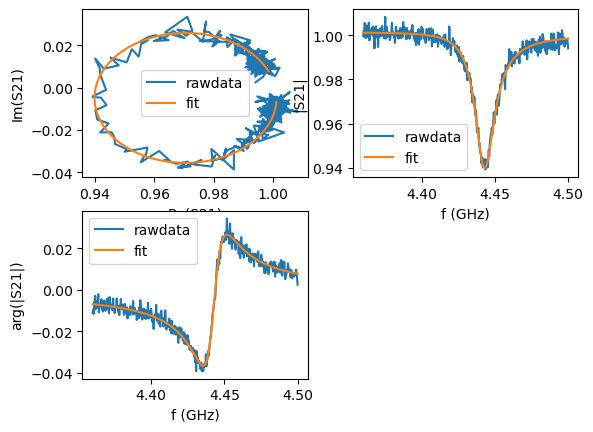

16
I1=2.1 mA: f0=4442436450.427516 Hz, Ql=267


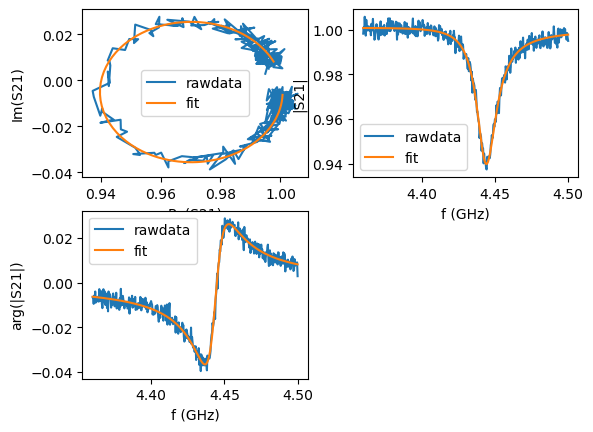

17
I1=2.16 mA: f0=4443495302.448809 Hz, Ql=268


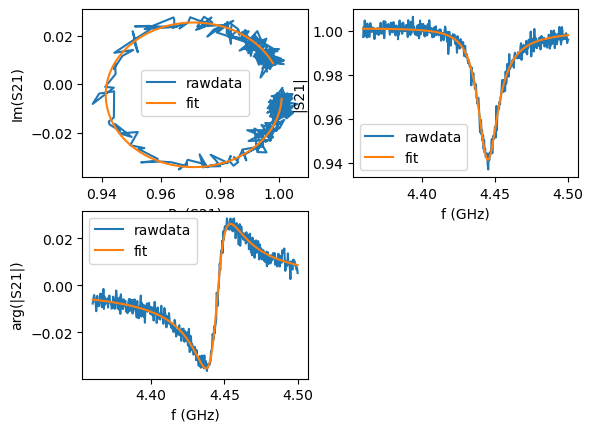

18
I1=2.22 mA: f0=4444538407.834274 Hz, Ql=260


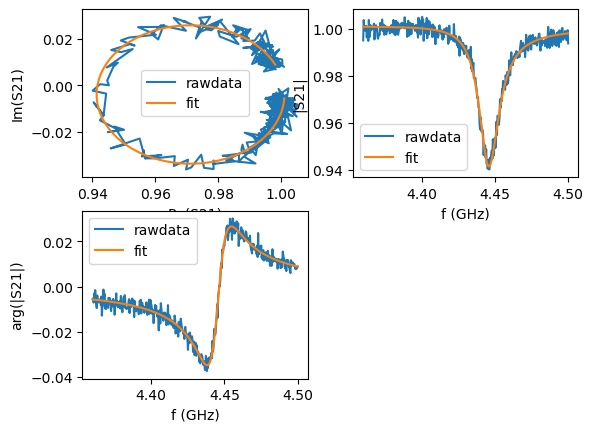

19
I1=2.28 mA: f0=4445284090.371063 Hz, Ql=263


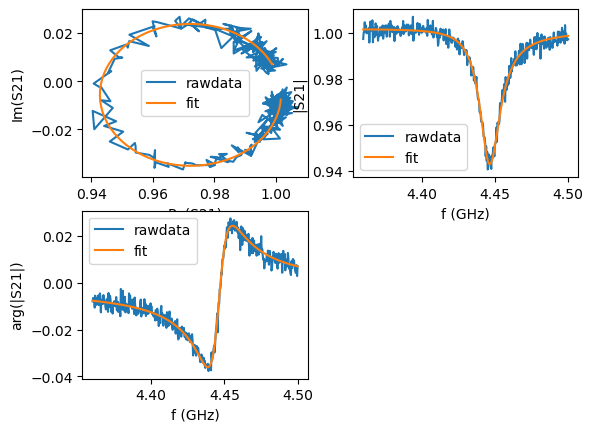

20
I1=2.34 mA: f0=4445920779.944117 Hz, Ql=258


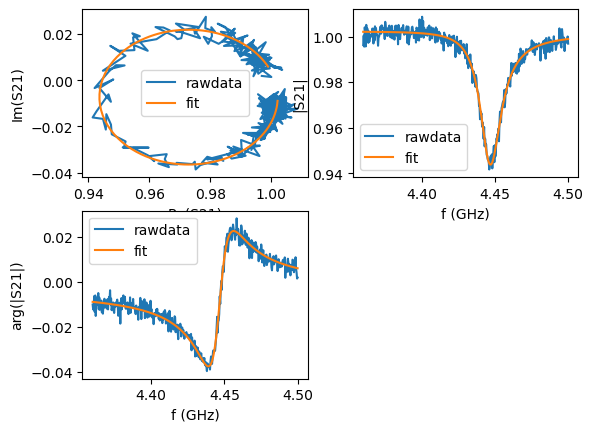

21
I1=2.4 mA: f0=4446307839.074989 Hz, Ql=253


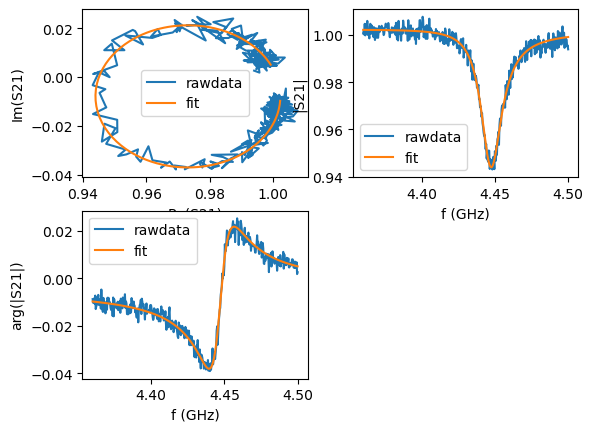

22
I1=2.46 mA: f0=4446822047.453755 Hz, Ql=255


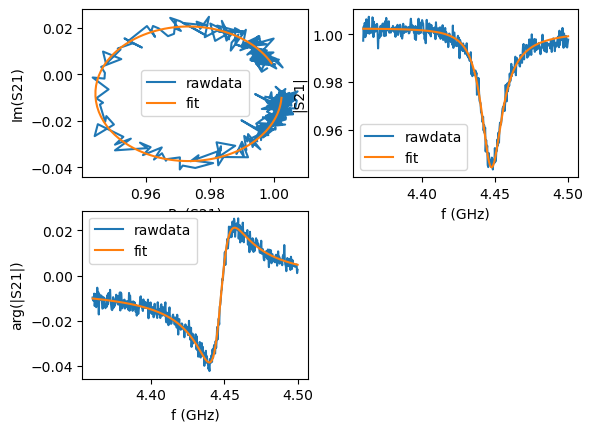

23
I1=2.52 mA: f0=4447032966.622506 Hz, Ql=252


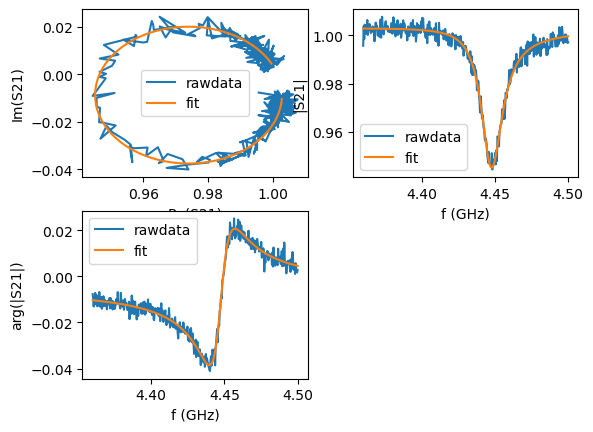

24
I1=2.58 mA: f0=4447097358.537511 Hz, Ql=250


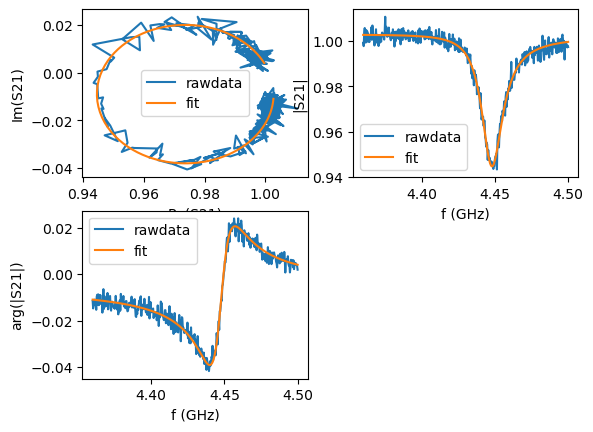

25
I1=2.64 mA: f0=4447385073.382576 Hz, Ql=252


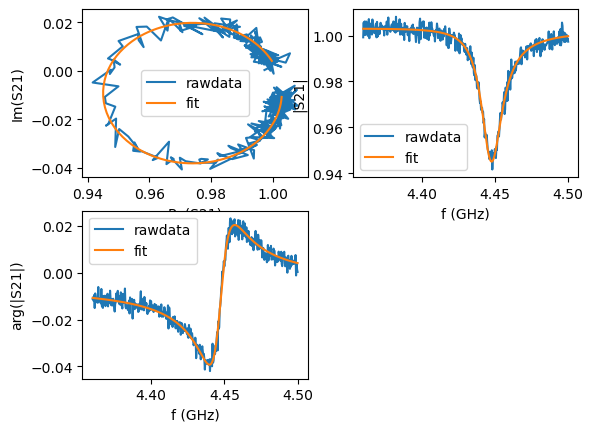

26
I1=2.7 mA: f0=4447058788.668844 Hz, Ql=253


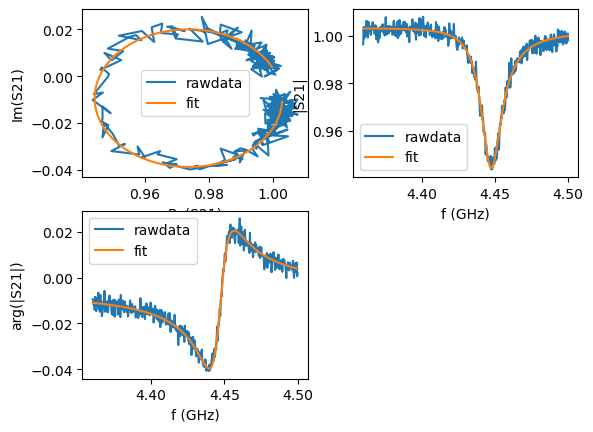

27
I1=2.76 mA: f0=4446824495.986046 Hz, Ql=255


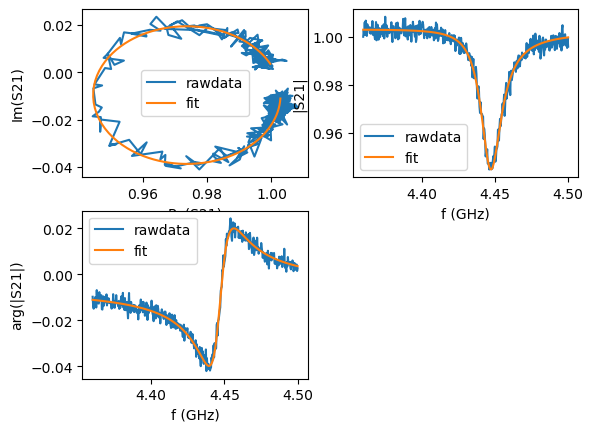

28
I1=2.82 mA: f0=4446623061.420755 Hz, Ql=257


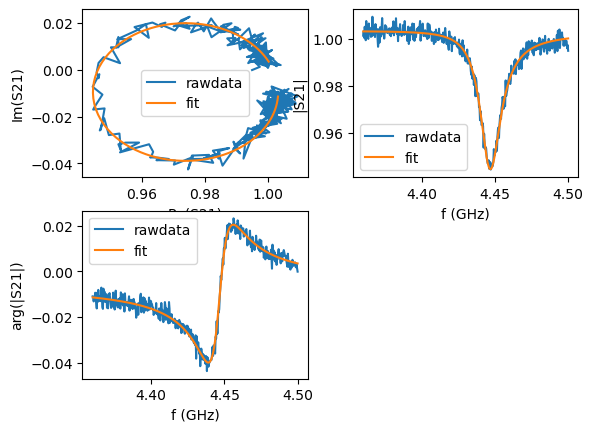

29
I1=2.88 mA: f0=4446272156.114187 Hz, Ql=255


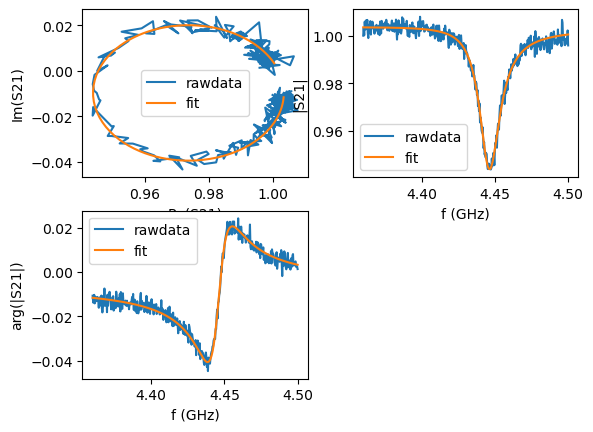

30
I1=2.94 mA: f0=4445710192.638446 Hz, Ql=257


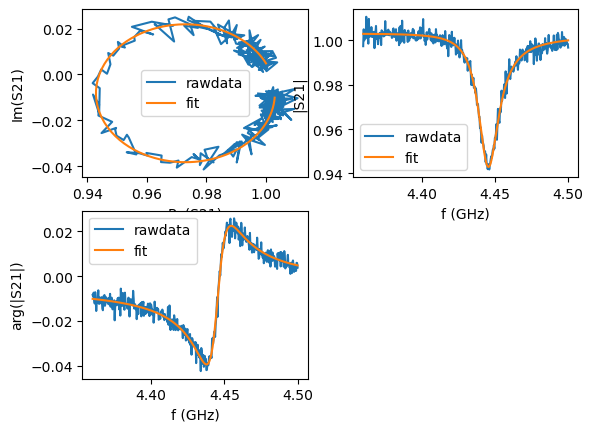

31
I1=3 mA: f0=4444944760.170314 Hz, Ql=258


In [9]:
for i in range(S21_complex_f3.shape[1]):
        if fit_results_dict_3[i] is not None:
            ports_dict_3[i].plotall()
            print(i)
            print(f"I1={I1_s3[i]:.3g} mA: f0={fit_results_dict_3[i]['fr']:.6f} Hz, Ql={fit_results_dict_3[i]['Ql']:.3g}")

In [9]:
fr_1 = np.full(len(fit_results_dict), np.nan)
Qi_1 = np.full(len(fit_results_dict), np.nan)
Qc_1 = np.full(len(fit_results_dict), np.nan)
Ql_1 = np.full(len(fit_results_dict), np.nan)
phi_0_1 = np.full(len(fit_results_dict), np.nan)

for i, r in enumerate(fit_results_dict.values()):
    if r is None:
        continue
    fr_1[i] = r['fr']
    Qi_1[i] = r['Qi_dia_corr']   # key names vary slightly by version — check port.fitresults.keys()
    Qc_1[i] = r['absQc']   # key names vary slightly by version — check port.fitresults.keys()
    Ql_1[i] = r['Ql']
    phi_0_1[i] = r['phi0']

In [98]:
r

{'Qi_dia_corr': 279.37642854768796,
 'Qi_no_corr': 279.6003222357617,
 'absQc': 4365.924349671957,
 'Qc_dia_corr': 4421.25118338747,
 'Ql': 262.7720098888082,
 'fr': 4444275359.869707,
 'theta0': -2.98322582047861,
 'phi0': 0.15836683791742692,
 'phi0_err': 0.014266381262233195,
 'Ql_err': 5.138248722802589,
 'absQc_err': 64.01283488147892,
 'fr_err': 167040.28921449557,
 'chi_square': 1.2091776643630912e-05,
 'Qi_no_corr_err': 5.625525439977256,
 'Qi_dia_corr_err': 5.619089020094368}

In [10]:
fr_2 = np.full(len(fit_results_dict_2), np.nan)
Qi_2 = np.full(len(fit_results_dict_2), np.nan)
Qc_2 = np.full(len(fit_results_dict_2), np.nan)
Ql_2 = np.full(len(fit_results_dict_2), np.nan)
phi_0_2 = np.full(len(fit_results_dict_2), np.nan)

for i, r in enumerate(fit_results_dict_2.values()):
    if r is None:
        continue
    fr_2[i] = r['fr']
    Qi_2[i] = r['Qi_dia_corr']  # key names vary slightly by version — check port.fitresults.keys()
    Qc_2[i] = r['absQc']  # key names vary slightly by version — check port.fitresults.keys()
    Ql_2[i] = r['Ql']
    phi_0_2[i] = r['phi0']
    Ql_2[5] = Ql_2[4] 
    Qi_2[5] = Qi_2[4]
    Qc_2[5] = Qc_2[4]
    fr_2[5] = fr_2[4]
    phi_0_2[5] = phi_0_2[4]

In [11]:
fr_3 = np.full(len(fit_results_dict_3), np.nan)
Qi_3 = np.full(len(fit_results_dict_3), np.nan)
Qc_3 = np.full(len(fit_results_dict_3), np.nan)
Ql_3 = np.full(len(fit_results_dict_3), np.nan)
phi_0_3 = np.full(len(fit_results_dict_3), np.nan)

for i, r in enumerate(fit_results_dict_3.values()):
    if r is None:
        continue
    fr_3[i] = r['fr']
    Qi_3[i] = r['Qi_dia_corr']  # key names vary slightly by version — check port.fitresults.keys()
    Qc_3[i] = r['absQc']  # key names vary slightly by version — check port.fitresults.keys()
    Ql_3[i] = r['Ql']
    phi_0_3[i] = r['phi0']
    Ql_3[0] = Ql_3[1]
    Qi_3[0] = Qi_3[1]
    Qc_3[0] = Qc_3[1]
    phi_0_3[0] = phi_0_3[1]
    fr_3[0] = fr_3[1]

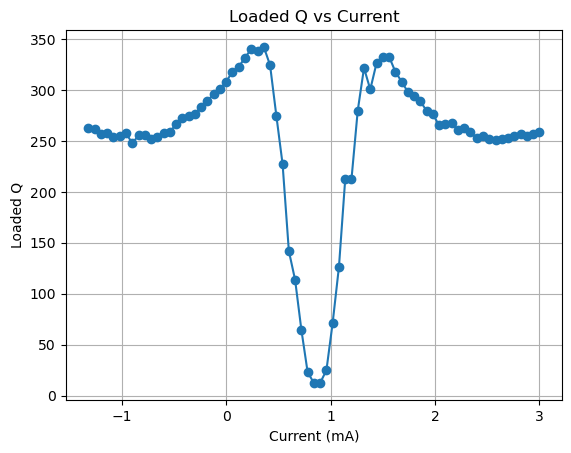

((2289,), 3861950000.0, 4500000000.0)

In [12]:
I = np.concatenate([I1_s1, I1_s2, I1_s3])
Ql = np.concatenate([Ql_1, Ql_2, Ql_3])
Qc = np.concatenate([Qc_1, Qc_2, Qc_3])
Qi = np.concatenate([Qi_1, Qi_2, Qi_3])
f0_shift = np.concatenate([fr_1, fr_2, fr_3])
Freq = np.concatenate([Freq_f1, Freq_f2, Freq_f3])
phi_0 = np.concatenate([phi_0_1, phi_0_2, phi_0_3])
plt.plot(I, Ql, '-o')
# # plt.plot(I1_s2, Ql_2, '-o')
# # plt.plot(I1_s3, Ql_3, '-o')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
#plt.legend(])
plt.show()
Freq.shape, Freq.min(), Freq.max()

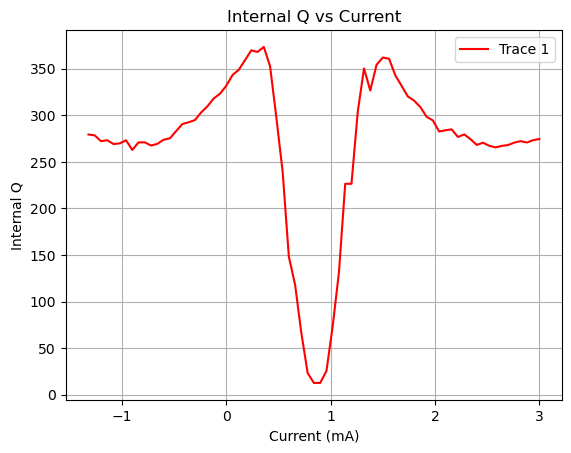

In [13]:
plt.plot(I, Qi, 'r')
plt.xlabel('Current (mA)')
plt.ylabel('Internal Q')
plt.title('Internal Q vs Current')
plt.grid(True)
plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

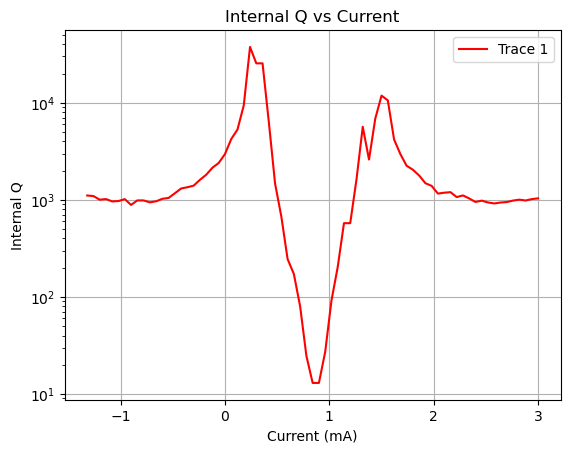

373.4373727188263

In [14]:
Q_R = np.zeros_like(Qi)
for i, q in enumerate(Qi):
    if q == np.max(Qi):
        Q_R[i] = Q_R[i-1]
    else:
        Q_R[i] = (1/q - 1/np.max(Qi))**(-1)
plt.semilogy(I, Q_R, 'r')
plt.xlabel('Current (mA)')
plt.ylabel('Internal Q')
plt.title('Internal Q vs Current')
plt.grid(True)
plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()
np.max(Qi)


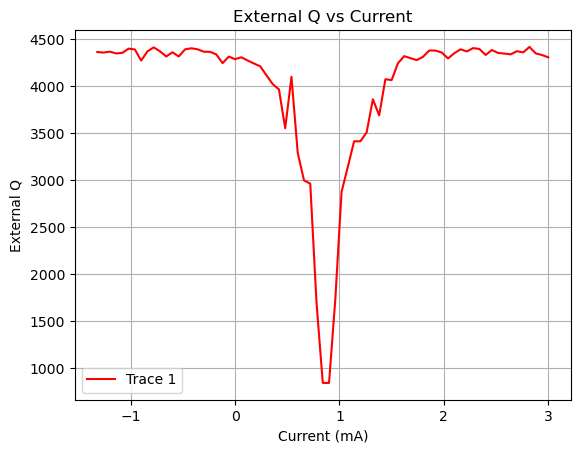

In [15]:
plt.plot(I, Qc, 'r')
plt.xlabel('Current (mA)')
plt.ylabel('External Q')
plt.title('External Q vs Current')
plt.grid(True)
plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

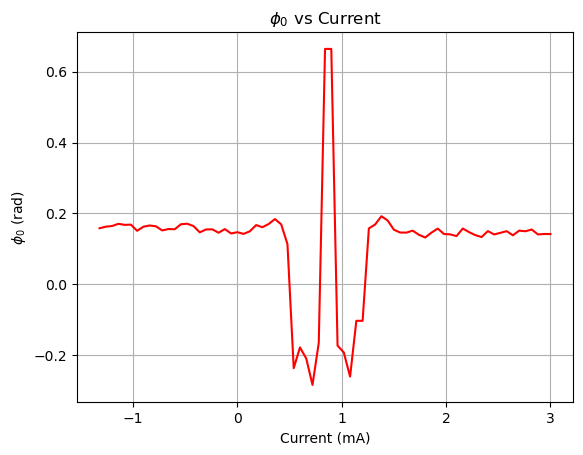

In [16]:
plt.plot(I, phi_0, 'r')
plt.xlabel('Current (mA)')
plt.ylabel(r'$\phi_0$ (rad)')
plt.title(r'$\phi_0$ vs Current')
plt.grid(True)
#plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

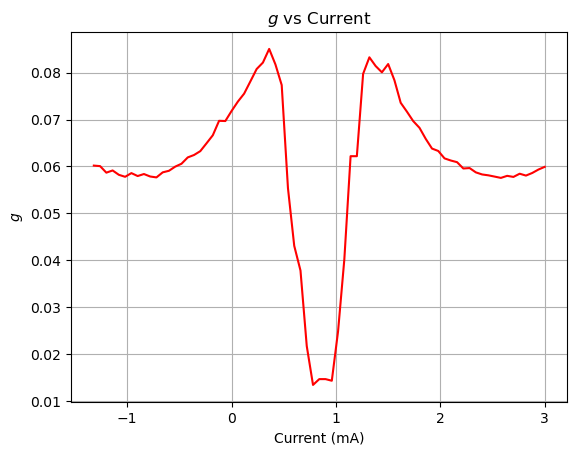

In [17]:
plt.plot(I, Ql/Qc, 'r')
plt.xlabel('Current (mA)')
plt.ylabel(r'$g$')
plt.title(r'$g$ vs Current')
plt.grid(True)
#plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

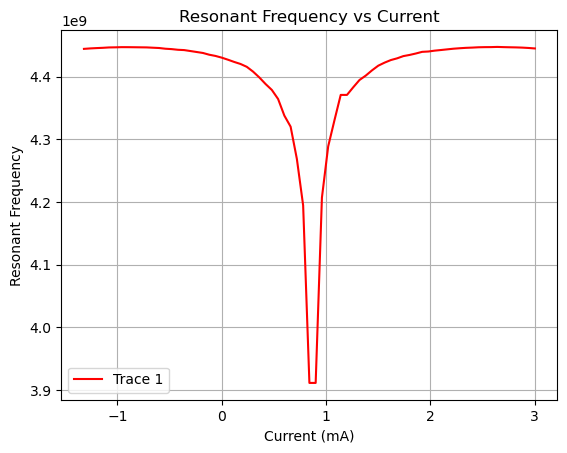

In [18]:
plt.plot(I, f0_shift, 'r')
plt.xlabel('Current (mA)')
plt.ylabel('Resonant Frequency')
plt.title('Resonant Frequency vs Current')
plt.grid(True)
plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

In [14]:
from scipy.special import ellipk
from scipy.signal import find_peaks, peak_widths
from scipy.constants import mu_0, epsilon_0
from scipy.optimize import root, curve_fit
from functools import partial
from scipy.io import loadmat
from scipy.optimize import least_squares

In [49]:
#natural constants
delta_0 = 1.76*1.38*10**(-23)*1.3
elec_c = 1.602*10**(-19)
phi_0 = 2.067*10**(-15)
h = 6.626*10**(-34)
hbar = h/(2*np.pi)

In [15]:
def del_sol(delta, a, phi_ext_val):
    
    lhs = delta + a * np.sin(delta)
    
    return lhs - phi_ext_val


# calculates the impedance of the coupling capacitor to the transmission line (not shown in the setup)
def c_cap(c_c, w):
    return np.array([[1,1/(1j*c_c*w)],[0,1]])

# calculates the impedance of the resonator
def tline(Z0, beta, L):
    return np.array([[np.cos(beta*L),1j*Z0*np.sin(beta*L)],[1j*(1/Z0)*np.sin(beta*L),np.cos(beta*L)]])


def Z_L(L_01, L_02, L_T, d, w, R):
    # R_n = (L_T*np.pi**2*delta_0)/(elec_c*phi_0)
    ZL01 = 1j*w*L_01
    ZL02 = 1j*w*L_02
    ZLT = 1j*w*L_T/np.cos(d)
    # ZCT = 1/(1j*w*CT)
    Z_squid = ZLT #(1/ZLT + 1/ZCT + 1/R_n)**(-1)
    ZL02R = (1/ZL02 + 1/R)**(-1)
    ZSQUID = (1/ZL01 + 1/(Z_squid + ZL02R))**(-1)
    
    return ZSQUID

def Z_tot(ZL, Z0, beta, l, c_c, w):
    x = beta*l
    Z_c = 1/(1j*w*c_c)
    return (Z0*((ZL + 1j*Z0*np.tan(x))/(Z0 + 1j*ZL*np.tan(x)))) + Z_c

def branch(Z):
    return np.array([[1,0], [1/Z, 1]])
    
#calculates the ABCD matrix
def ABCD(M1, M2, M3):
    full_M = M1 @ M2 @ M3 
    
    return full_M
#Calculates the S21 parameter
def S21(A, B, C, D, Z0):
    return 2/(A + B/Z0 + C*Z0 + D)


def current_to_flux(I, M, o):
    return M*I + o


In [16]:
def solve_delta(phi_ext, a):
    phi_ext = np.asarray(phi_ext)
    delta = np.zeros_like(phi_ext, dtype=float)
    order = np.argsort(phi_ext)          # continuity in phi_ext, not array position
    d0 = 0.0
    for idx in order:
        sol = root(del_sol, d0, args=(a, phi_ext[idx]))
        delta[idx] = sol.x[0]
        d0 = sol.x[0]
    return delta

def S21_fit_func(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, Z0=50):
    """
    X = (I, f): current (A) and frequency (Hz) arrays, same length (elementwise pairs).
    Fit params: L0 (=L01=L02), LT, L_l, C_l, C_c, R_j
    Fixed:      l_f (resonator length), M, O (current -> flux calibration)
    """
    I, f = X
    w = 2 * np.pi * f
    phi_ext = M * I + O #np.pi - 0.5 -0.25 - 0.25 - 0.25

    a = 2 * L0 / LT
    delta = solve_delta(phi_ext, a)

    beta = w * np.sqrt(L_l * C_l)
    ZL = Z_L(L0, L0, LT, delta, w, R_j)
    Ztot = Z_tot(ZL, Z0, beta, l_f, C_c, w)

    return 2 / (2 + Z0 / Ztot)

def S21_fit_mag_dB(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f):
    S21 = S21_fit_func(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f)
    return 20 * np.log10(np.abs(S21))

In [18]:
def calc_cpw_param_set(
    center_width: float, gap_width: float, substrate_r: float, metal_thickness: float
):
    a = center_width / 2
    b = center_width / 2 + gap_width
    d = metal_thickness / (2 * np.pi)

    u1 = (
        a
        + d / 2
        + 3 / 2 * np.log(2) * d
        - d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    u2 = (
        b
        - d / 2
        - 3 / 2 * np.log(2) * d
        + d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    k1 = u1 / u2
    k2 = np.sqrt(1 - k1**2)
    c = 2 * epsilon_0 * ellipk(k1) / ellipk(k2) * (1 + substrate_r)

    d = d/2
    u1 = a+d/2+3/2*np.log(2)*d-d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    u2 = b-d/2-3/2*np.log(2)*d+d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    k1 = u1/u2
    k2 = np.sqrt(1-k1**2)
    l = mu_0/4*ellipk(k2)/ellipk(k1)

    lambda_eff = 50e-9  # m, effective field penetration depth
    k = a/b
    g_ctr = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*a/metal_thickness)-k*np.log((1+k)/(1-k)))
    g_gnd = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*b/metal_thickness)-k*np.log((1+k)/(1-k)))
    g = g_ctr+g_gnd
    l_ki = g*mu_0*lambda_eff
    l_tot = l+l_ki

    return {'inductance': l_tot, 'capacitance': c}

def calc_target_length(target_frequency: float, cpw_param_set: dict):
    return 1e6 / (4 * target_frequency * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



def calc_target_frequency(target_length: float, cpw_param_set: dict):
    return 1e6 / (4 * target_length * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



resonator_widths = [7, 10, 7]
#################################3

res_cpw_param_set = calc_cpw_param_set(
    center_width= resonator_widths[1]*1e-6, 
    gap_width=resonator_widths[0]*1e-6, 
    substrate_r=11.6, 
    metal_thickness=200e-9
)
l = calc_target_length(5e9, res_cpw_param_set)
R_L = l/1e6
L_l = res_cpw_param_set['inductance']
C_l = res_cpw_param_set['capacitance']
R_L

0.0056348805631426455

In [19]:
def lorentzian_dip_power(f, f0, Q_L, baseline, Q_e_inv):
    """
    Fit model for |S21|^2 in terms of Q factors directly.
    Q_e_inv = 1/Q_e (easier to fit as a free parameter)
    """
    depth_amplitude = Q_L * Q_e_inv          # = Q_L / Q_e
    lorentz = depth_amplitude / (1 + 4 * Q_L**2 * ((f - f0)/f0)**2)
    # |S21|^2 = baseline * |1 - lorentz|^2
    return baseline * (1 - lorentz)**2


# def calculate_q_factors(freq, S21_vals):

#     # Ensure freq is a flat 1D array
#     #freq = np.asarray(freq).flatten()
#     n_flux = S21_vals.shape[1]
    
#     q_loaded = np.zeros(n_flux)
#     q_internal = np.zeros(n_flux)
#     q_external = np.zeros(n_flux)
#     f0_fits = np.zeros(n_flux)
    
#     for i in range(n_flux):
#         power = np.abs(S21_vals[:, i])**2
        
#         baseline_guess = np.max(power)
#         min_idx = np.argmin(power)
#         f0_guess = freq[min_idx]
#         S21_min = np.sqrt(power[min_idx] / baseline_guess)
        
#         # Estimate df (FWHM) by finding points below the half-depth
#         half_max = baseline_guess - (baseline_guess - power[min_idx]) / 2.0
#         below_half = np.where(power < half_max)[0]
        
#         df_guess = freq[below_half[-1]] - freq[below_half[0]]

#         Q_L_guess = f0_guess/df_guess
        
#         dip = np.clip(1.0-S21_min, 1e-6, 2.0)
#         Qe_inv_guess = dip/Q_L_guess
                 
#         p0 = [f0_guess, Q_L_guess, baseline_guess, Qe_inv_guess]
        
#         popt, _ = curve_fit(lorentzian_dip_power, freq, power,
#                             p0=p0, maxfev=2000)
#         f0_fit, Q_L_fit, _, Qe_inv_fit = popt
#         Q_L_fit = np.abs(Q_L_fit)
#         Q_e_fit = 1.0 / np.abs(Qe_inv_fit)
        
#         Q_i_fit = 1.0 / (1.0/Q_L_fit - 1.0/Q_e_fit)

#         q_loaded[i]   = Q_L_fit
#         q_external[i] = Q_e_fit
#         q_internal[i] = Q_i_fit
#         f0_fits[i]    = f0_fit

#     return q_loaded, q_internal, q_external, f0_fits


def calculate_q_factors(freq, S21_vals, min_pts=6):
    n = S21_vals.shape[1]
    q_loaded, q_internal, q_external, f0_fits = (np.full(n, np.nan) for _ in range(4))
    df = freq[1] - freq[0]

    for i in range(n):
        power = np.abs(S21_vals[:, i])**2
        k = np.argmin(power)
        if k == 0 or k == len(freq) - 1:
            continue                                   # dip at window edge: no f0, no Q

        y0, y1, y2 = power[k-1], power[k], power[k+1]  # f0: parabolic interpolation, always available
        den = y0 - 2*y1 + y2
        f0_fits[i] = freq[k] + (0.5*(y0 - y2)/den*df if den != 0 else 0.0)

        base = power.max()
        half = base - (base - y1)/2
        below = np.where(power < half)[0]
        if len(below) < min_pts or len(below) > len(freq)//4:
            continue                                   # unresolved or too broad: skip Q only

        df_guess = freq[below[-1]] - freq[below[0]]
        QL0 = freq[k]/df_guess
        dip = np.clip(1 - np.sqrt(y1/base), 1e-6, 0.99)
        try:
            popt, _ = curve_fit(lorentzian_dip_power, freq, power,
                                p0=[freq[k], QL0, base, dip/QL0], maxfev=2000)
        except (RuntimeError, ValueError):
            continue
        f0_fit, QL, _, QeInv = popt
        QL, Qe = abs(QL), 1/abs(QeInv)
        if abs(f0_fit - freq[k]) > 5*df_guess or not (1/QL - 1/Qe) > 0:
            continue                                   # runaway or Q_L/Q_e >= 1: reject
        q_loaded[i], q_external[i] = QL, Qe
        q_internal[i] = 1/(1/QL - 1/Qe)
    return q_loaded, q_internal, q_external, f0_fits

# import warnings
# from resonator_tools import circuit

# def calculate_q_factors(freq, S21_vals):
#     """resonator_tools notch-port fit on each column of complex S21_vals.
#     Returns q_loaded, q_internal, q_external, f0 (NaN where the fit fails)."""
#     n_flux = S21_vals.shape[1]
#     q_loaded   = np.full(n_flux, np.nan)
#     q_internal = np.full(n_flux, np.nan)
#     q_external = np.full(n_flux, np.nan)
#     f0_fits    = np.full(n_flux, np.nan)

#     for i in range(n_flux):
#         try:
#             with warnings.catch_warnings():
#                 warnings.simplefilter("ignore")
#                 port = circuit.notch_port(freq, S21_vals[:, i])
#                 port.autofit(electric_delay=0)
#             r = port.fitresults
#             q_loaded[i]   = r["Ql"]
#             q_internal[i] = r["Qi_dia_corr"]
#             q_external[i] = r["Qc_dia_corr"]
#             f0_fits[i]    = r["fr"]
#         except Exception:
#             pass   # leave NaN, handled in the residual function
#     return q_loaded, q_internal, q_external, f0_fits

In [47]:
# def model_q_factors(I_arr, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds, n_freq=4000):
#     """Generate dense model S21 per current, extract Q_i/Q_ext/f0 via the same
#     Lorentzian-fit machinery used on the real data."""
#     f_dense = np.linspace(*f_bounds, n_freq)
#     S21_grid = np.zeros((n_freq, len(I_arr)), dtype=complex)

#     for k, I_val in enumerate(I_arr):
#         S21_grid[:, k] = S21_fit_func(
#             (np.full(n_freq, I_val), f_dense),
#             L0, LT, L_l, C_l, C_c, R_j, M, O, l_f
#         )

#     q_L, q_i, q_e, f0_arr = calculate_q_factors(f_dense, S21_grid)
#     return q_L, q_i, q_e, f0_arr

# def model_q_factors(I_arr, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds, n_freq=4000, Z0=50):
#     f_dense = np.linspace(*f_bounds, n_freq)
#     w = 2*np.pi*f_dense
#     beta = w*np.sqrt(L_l*C_l)

#     # delta depends only on the current, so solve it once per current (73 solves instead of 292,000)
#     delta = solve_delta(M*np.asarray(I_arr) + O, 2*L0/LT)

#     S21_grid = np.empty((n_freq, len(I_arr)), dtype=complex)
#     for k, d in enumerate(delta):
#         ZL = Z_L(L0, L0, LT, d, w, R_j)
#         Ztot = Z_tot(ZL, Z0, beta, l_f, C_c, w)
#         S21_grid[:, k] = 2/(2 + Z0/Ztot)

#     return calculate_q_factors(f_dense, S21_grid)
def model_q_factors(I_arr, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds, n_freq=4000, Z0=50):
    I_arr = np.asarray(I_arr)
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, 2*L0/LT)

    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Z0/Z_tot(Z_L(L0, L0, LT, d, w, R_j), Z0, beta, l_f, C_c, w))

    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    q_L, q_i, q_e, f0 = calculate_q_factors(f_dense, S_grid)

    # retry failed points on windows centred on f0, widening until the Lorentzian fit is accepted
    for k in np.where(~np.isfinite(q_i) & np.isfinite(f0))[0]:
        for span in (2e6, 10e6, 50e6, 200e6, 600e6, 800e6, 1e9, 1.2e9, 1.4e9, 1.8e9, 2e9, 2.5e9, 3e9):
            f_z = np.linspace(f0[k] - span, f0[k] + span, 1000)
            qL, qi, qe, f0z = calculate_q_factors(f_z, S_of(delta[k], f_z)[:, None])
            if np.isfinite(qi[0]):
                q_L[k], q_i[k], q_e[k], f0[k] = qL[0], qi[0], qe[0], f0z[0]
                break
    return q_L, q_i, q_e, f0

In [57]:
(I.min() -I.max())*1e-6

-4.32e-06

In [48]:
# I = np.concatenate([I1_s1, I1_s2, I1_s3])
# Ql = np.concatenate([Ql_1, Ql_2, Ql_3])
# Qc = np.concatenate([Qc_1, Qc_2, Qc_3])
# Qi = np.concatenate([Qi_1, Qi_2, Qi_3])

# PENALTY_f0 = 500   # in log10(Q) units; also used for f0 (MHz) on failed points
# PENALTY_Qi = 10.0   # in log10(Q) units; also used for f0 (MHz) on failed points


# def summary_residuals_QL_f0(params, I_arr, Qi_data, f0_data,l_f, f_bounds):
#     L0, LT, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
#     N = len(I_arr)
#     a, LT, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
#     L0 = a * LT / 2
#     try:
#         q_L, q_i, q_e, f0 = model_q_factors(I_arr, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
#     except Exception:
#       return np.full(2*len(I_arr), PENALTY)

#     # QR = (1/Qi_data - 1/Q_alpha)**(-1)   

#     # ok = np.isfinite(q_i) & (q_i > 0) & np.isfinite(f0)
#     # res_Qi = np.full(len(I_arr), PENALTY)
#     # res_f0 = np.full(len(I_arr), PENALTY)
#     # res_Qi[ok] = np.log10(q_i[ok]) - np.log10(QR[ok])
#     # res_f0[ok] = (f0[ok] - f0_data[ok]) / 1e6
#     res_f0 = np.where(np.isfinite(f0), (f0 - f0_data)/1e6, PENALTY_f0)  # MHz residuals, penalty for failed points
#     res_Qi = np.zeros(len(I_arr))                       # unresolved points are left out of the Q_i fit
#     okq = np.isfinite(q_i) & (q_i > 0)
#     res_Qi[okq] = np.log10(1/(1/q_i[okq] + 1/Q_alpha)) - np.log10(Qi_data[okq])
#     return np.concatenate([res_Qi, res_f0])

    # w = pole_weights(I_arr*1e6, M, O_fixed)

    # res_QL = (np.log10(q_L) - np.log10(QL_data)) #* w
    # res_f0 = ((f0 - f0_data) / 1e6) #* w
    # #res_Qe = (np.log10(q_e) - np.log10(Qext_all)) #* w

    # return np.concatenate([res_QL, res_f0])

# PENALTY = 10.0   # in log10(Q) units; also used for f0 (MHz) on failed points

# def summary_residuals_Qi_f0(params, I_arr, f0_data, Q_i, l_f, f_bounds):
#     a, LT, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
#     L0 = a * LT / 2
#     try:
#         q_L, q_i, q_e, f0 = model_q_factors(I_arr, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
#     except Exception:
#         return np.full(2*len(I_arr), PENALTY)

#     QR = (1/Q_i - 1/Q_alpha)**(-1)   

#     ok = np.isfinite(q_i) & (q_i > 0) & np.isfinite(f0)
#     res_Qi = np.full(len(I_arr), PENALTY)
#     res_f0 = np.full(len(I_arr), PENALTY)
#     res_Qi[ok] = np.log10(q_i[ok]) - np.log10(QR[ok])
#     res_f0[ok] = (f0[ok] - f0_data[ok]) / 1e6
#     return np.concatenate([res_Qi, res_f0])


PENALTY_F0 = 500.0     # MHz
F0_SCALE = 20.0        # MHz, tolerance
QI_SCALE = 0.1         # log10 units, tolerance

def summary_residuals_QL_f0(params, I_arr, Qi_data, f0_data, l_f, f_bounds):
    a, LT, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
    L0 = a * LT / 2
    n = len(I_arr)
    try:
        q_L, q_i, q_e, f0 = model_q_factors(I_arr, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
    except Exception as e:
        print("model failed:", repr(e))              # don't swallow errors silently
        return np.full(2*n, PENALTY_F0 / F0_SCALE)

    res_f0 = np.where(np.isfinite(f0), (f0 - f0_data)/1e6, PENALTY_F0) / F0_SCALE

    res_Qi = np.zeros(n)                              # unresolved points: no contribution
    okq = np.isfinite(q_i) & (q_i > 0)
    res_Qi[okq] = (np.log10(1/(1/q_i[okq] + 1/Q_alpha)) - np.log10(Qi_data[okq])) / QI_SCALE
    return np.concatenate([res_Qi, res_f0])


O_guess = np.pi - 1.25
M_mag = 2*np.pi / np.abs(((I.min() -I.max())*1e-6))
#L_l = 4.9137e-7
#C_l = 1.2861e-10

p0 = [0.979, 0.412e-9, L_l, C_l, 13e-15, 20, M_mag, O_guess, 400]
lower = [0.8, 0.2e-9, 0.5*L_l, 0.5*C_l, 10e-15, 15,  -1.1*M_mag, -np.pi, 300]
upper = [0.98, 0.55e-9, 1.5*L_l, 1.5*C_l, 30e-15, 30, 1.1*M_mag, np.pi, 500]

res = least_squares(
    summary_residuals_QL_f0, p0,
    args=(I*1e-6, Qi, f0_shift, R_L, (Freq.min()-1e9, Freq.max()+1e9)),
    bounds=(lower, upper), x_scale='jac'
)
a_f, LT_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, Q_alpha_f = res.x
print(res.x, " a =", a_f*LT_f/2, " cost:", res.cost)

[9.42579577e-01 2.64110914e-10 5.78161351e-07 1.54010877e-10
 1.96516720e-14 2.10242808e+01 9.44987554e+05 2.32030433e+00
 3.24649743e+02]  a = 1.2447277706867978e-10  cost: 20.490345405801065


In [41]:
import time
t = time.time()
p0 = [0.979, 0.412e-9, L_l, C_l, 13e-15, 18, M_mag, O_guess, 400]
r = summary_residuals_QL_f0(p0, I*1e-6, Qi, f0_shift, R_L, (Freq.min()-1e9, Freq.max()+1e9))
print(time.time() - t, "s per evaluation")
print(np.isfinite(r).all(), (r == PENALTY_F0).sum(), "of", len(r), "penalized")

0.30666661262512207 s per evaluation
True 0 of 146 penalized


In [34]:
f = np.linspace(Freq.min()-1e9, Freq.max()+1e9, 4000)
for k in range(0, 73, 1):
    S = S21_fit_func((np.full(4000, I[k]*1e-6), f), p0[0]*p0[1]/2, p0[1], p0[2], p0[3], p0[4], p0[5], p0[6], p0[7], R_L)
    p = np.abs(S)**2
    n_below = (p < p.max() - (p.max()-p.min())/2).sum()
    print(k, "argmin idx", p.argmin(), "of 4000 | points below half-depth:", n_below)

0 argmin idx 2724 of 4000 | points below half-depth: 21
1 argmin idx 2724 of 4000 | points below half-depth: 21
2 argmin idx 2724 of 4000 | points below half-depth: 21
3 argmin idx 2724 of 4000 | points below half-depth: 22
4 argmin idx 2723 of 4000 | points below half-depth: 21
5 argmin idx 2723 of 4000 | points below half-depth: 21
6 argmin idx 2722 of 4000 | points below half-depth: 21
7 argmin idx 2721 of 4000 | points below half-depth: 21
8 argmin idx 2720 of 4000 | points below half-depth: 21
9 argmin idx 2719 of 4000 | points below half-depth: 20
10 argmin idx 2718 of 4000 | points below half-depth: 20
11 argmin idx 2716 of 4000 | points below half-depth: 19
12 argmin idx 2714 of 4000 | points below half-depth: 19
13 argmin idx 2712 of 4000 | points below half-depth: 18
14 argmin idx 2710 of 4000 | points below half-depth: 17
15 argmin idx 2708 of 4000 | points below half-depth: 17
16 argmin idx 2705 of 4000 | points below half-depth: 16
17 argmin idx 2702 of 4000 | points below

In [99]:
print(res.x, " a =", a_f*LT_f/2, " cost:", res.cost)

[9.79135533e-01 5.10630429e-10 5.19096524e-07 1.37227552e-10
 2.07161905e-14 1.83829577e+01 1.40422698e+06 1.88911919e+00
 4.00064665e+02]  a = 2.4998819874471106e-10  cost: 10231734.658528794


In [ ]:
out = model_q_factors(I*1e-6, *p0[:8], p0[8], R_L, (Freq.min(), Freq.max()))
print(type(out), len(out))
q_L, q_i, q_e, f0_arr = out
print(np.isfinite(f0_arr).sum(), np.isfinite(q_i).sum(), (q_i > 0).sum())
print(f0_arr[:5], f0_shift[:5])

<class 'tuple'> 4
73 73 73
[4.82445225e+09 4.82439894e+09 4.82404233e+09 4.82337990e+09
 4.82240702e+09] [4.44427536e+09 4.44499635e+09 4.44551708e+09 4.44595124e+09
 4.44655149e+09]


In [54]:
f0_calc = 1/(4*l*np.sqrt(Ll_f*Cl_f))
Qi.shape, Q_alpha_f.shape

((73,), ())

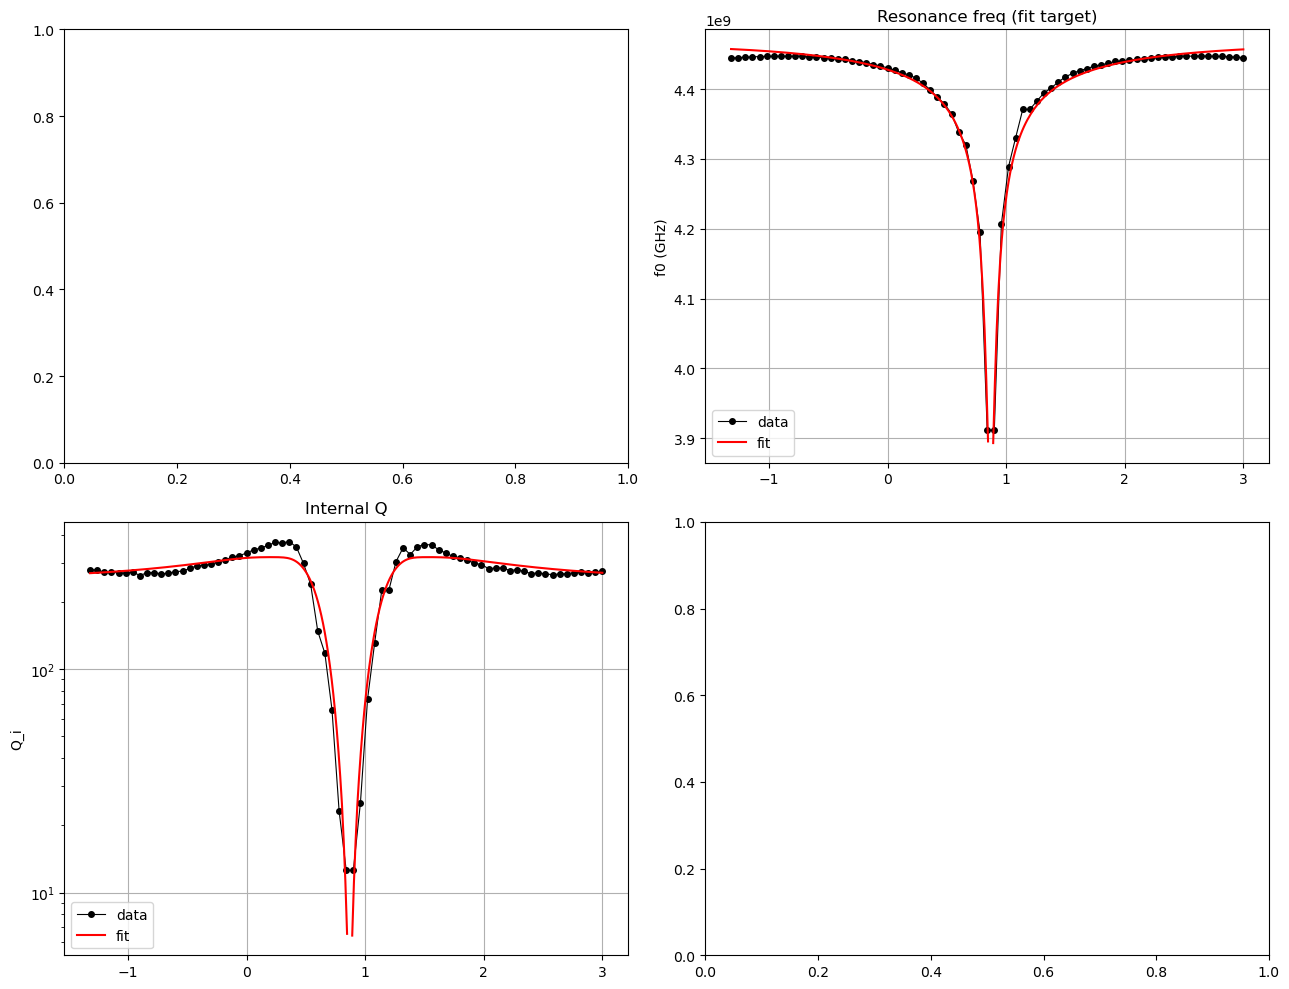

In [49]:
I_plot_uA = np.linspace(I.min(), I.max(), 300)
I_plot_A = I_plot_uA * 1e-6
QL_model, q_i_model, q_e_model, f0_model = model_q_factors(
    I_plot_A, a_f*LT_f/2, LT_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, R_L, (Freq.min(), Freq.max())
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
# axes[0,0].plot(I, Ql, 'ko-', ms=4, lw=0.8, label='data')
# axes[0,0].plot(I_plot_uA, QL_model, 'r-', lw=1.5, label='fit')
# axes[0,0].set_ylabel('Q_L'); axes[0,0].set_title('Loaded Q (fit target)'); axes[0,0].legend(); axes[0,0].grid(True)

axes[0,1].plot(I, f0_shift, 'ko-', ms=4, lw=0.8, label='data')
axes[0,1].plot(I_plot_uA, f0_model, 'r-', lw=1.5, label='fit')
axes[0,1].set_ylabel('f0 (GHz)'); axes[0,1].set_title('Resonance freq (fit target)'); axes[0,1].legend(); axes[0,1].grid(True)

axes[1,0].plot(I, Qi, 'ko-', ms=4, lw=0.8, label='data')
axes[1,0].plot(I_plot_uA, (1/q_i_model + 1/Q_alpha_f)**(-1), 'r-', lw=1.5, label='fit')
axes[1,0].set_ylabel('Q_i'); axes[1,0].set_yscale('log'); axes[1,0].set_title('Internal Q'); axes[1,0].legend(); axes[1,0].grid(True)

# axes[1,1].plot(I, Qc, 'ko-', ms=4, lw=0.8, label='data')
# axes[1,1].plot(I_plot_uA, q_e_model, 'r-', lw=1.5, label='implied')
# # axes[1,1].set_ylabel('Q_ext'); axes[1,1].set_title('External Q (diagnostic only)'); axes[1,1].legend(); axes[1,1].grid(True)
plt.tight_layout(); plt.show()

In [50]:
bad = ~np.isfinite(q_i_model)
print(I_plot_uA[bad], np.isfinite(f0_model[bad]).all())


[0.86167224 0.8761204 ] False


In [65]:
k = np.argmin(np.abs(I_plot_uA - 0.8761))          # one of the bad points
I_k = I_plot_A[k]
d = solve_delta(Cc_dummy := Mf*I_k + Of, 2*(a_f*LT_f/2)/LT_f) if False else None  # see below

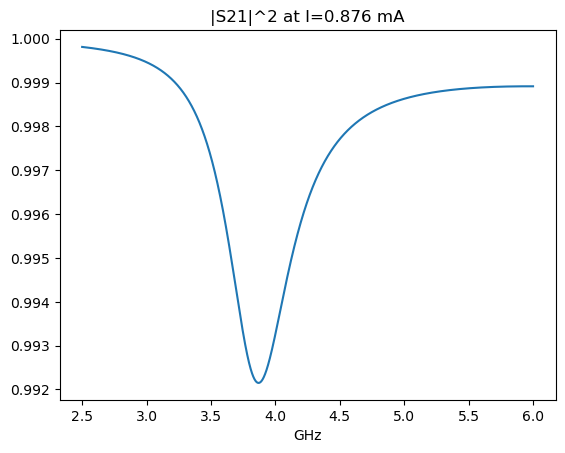

min |S21|: 0.9960672486863856  f0: 3.8695461932741595 GHz


In [66]:
M_, O_ = M_f, O_f
L0_ = a_f*LT_f/2
d = solve_delta(np.array([M_*I_plot_A[k] + O_]), 2*L0_/LT_f)[0]

def S_of(f):
    w = 2*np.pi*f
    beta = w*np.sqrt(Ll_f*Cl_f)
    return 2/(2 + 50/Z_tot(Z_L(L0_, L0_, LT_f, d, w, Rj_f), 50, beta, R_L, Cc_f, w))

f = np.linspace(2.5e9, 6e9, 8000)
p = np.abs(S_of(f))**2
plt.plot(f/1e9, p); plt.xlabel('GHz'); plt.title(f'|S21|^2 at I={I_plot_uA[k]:.3f} mA'); plt.show()
print("min |S21|:", np.sqrt(p.min()), " f0:", f[p.argmin()]/1e9, "GHz")